# NN_L14_fewshot_eurosat

**EuroSAT test accuracy against labelled images per class: logistic regression on CLIP ViT-B/16 embeddings (5 seeds) and a CNN trained from scratch (3 seeds), with zero-shot CLIP and the CNN on all training images as references.**

Neural Networks and Deep Learning (NN), Lecture 14 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L14/NN_L14_fewshot_eurosat/NN_L14_fewshot_eurosat.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

probe, 16 per class (%) = 84.7   [fewshot.probe.16.mean]
CNN, 16 per class (%) = 78.5   [fewshot.cnn.16.mean]
probe, 128 per class (%) = 91.6   [fewshot.probe.128.mean]
CNN, 128 per class (%) = 94.1   [fewshot.cnn.128.mean]
CNN on all training images (%) = 97.4   [cnn_full.mean]


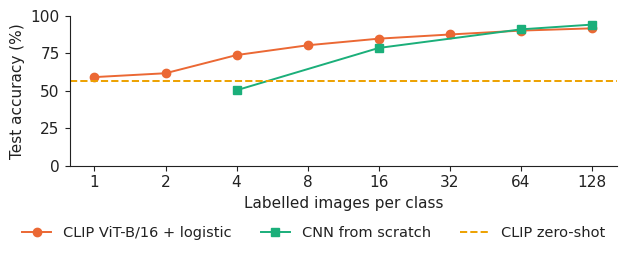

In [3]:
RES = REPO + 'lectures/L14/results/'
Fq = pd.read_csv(RES + 'fewshot_eurosat.csv')
Z = pd.read_csv(RES + 'eurosat_zeroshot.csv')
g = Fq.groupby(['method', 'k'])['acc'].mean().mul(100)
for k in (16, 128):
    show(f'fewshot.probe.{k}.mean', f'probe, {k} per class (%)', round(float(g[('probe', k)]), 1))
    show(f'fewshot.cnn.{k}.mean', f'CNN, {k} per class (%)', round(float(g[('cnn', k)]), 1))
show('cnn_full.mean', 'CNN on all training images (%)', round(float(Fq[Fq.method == 'cnn_full'].acc.mean() * 100), 1))
zs = max(100 * (Z[c] == Z['true']).mean() for c in Z.columns if c[:3] in ('B32', 'B16'))
fig, ax = plt.subplots(figsize=(6.4, 2.6))
pk = g['probe']
ck = g['cnn']
ax.plot(np.log2(pk.index), pk.values, marker='o', color=PAL['model'], label='CLIP ViT-B/16 + logistic')
ax.plot(np.log2(ck.index), ck.values, marker='s', color=PAL['benchmark'], label='CNN from scratch')
ax.axhline(zs, ls='--', color=PAL['alt'], label='CLIP zero-shot')
ax.set_xticks(np.log2(pk.index))
ax.set_xticklabels(pk.index)
ax.set_xlabel('Labelled images per class')
ax.set_ylabel('Test accuracy (%)')
ax.set_ylim(0, 100)
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('fewshot_eurosat.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()